# Proyecto de Minería de Datos: Clusterización K-Means
## GeoRisk AI — Segmentación de condiciones geoclimáticas en Bolivia

**Objetivo.** Aplicar K-Means al conjunto de datos de GeoRisk AI para identificar perfiles de observaciones con condiciones climáticas y topográficas similares. La segmentación complementa al modelo supervisado de predicción: no determina por sí sola una alerta, sino que ayuda a comprender patrones presentes en los datos.

> Nota: el conjunto utilizado es sintético y sus resultados tienen fines académicos; no deben emplearse para decisiones reales de emergencia.

## 1. Descripción del análisis

Las variables elegidas para formar los clusters son seis mediciones numéricas disponibles antes de conocer si ocurrió un deslizamiento:

- precipitación acumulada en 24 horas, 3 días y 7 días;
- pendiente del terreno;
- elevación;
- humedad del suelo.

No se utilizan `indice_riesgo_deslizamiento` ni `deslizamiento_ocurrido` para entrenar K-Means, porque son variables de resultado. Se reservan exclusivamente para interpretar los grupos una vez creados.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')
RANDOM_STATE = 42
sns.set_theme(style='whitegrid', palette='deep')
pd.set_option('display.max_columns', 30)

In [2]:
DATASET = Path('Dataset_10000_Bolivia_Sintetico.csv')
if not DATASET.exists():
    DATASET = Path('caso8') / DATASET

df = pd.read_csv(DATASET)
print(f'Dimensiones: {df.shape[0]:,} filas y {df.shape[1]} columnas')
print(f'Valores nulos: {int(df.isna().sum().sum())}')
df.head()

Dimensiones: 10,000 filas y 13 columnas
Valores nulos: 0


,id_registro,departamento,precipitacion_24h_mm,precipitacion_3d_mm,precipitacion_7d_mm,pendiente_grados,elevacion_m,humedad_pct,tipo_suelo,geologia,score_riesgo_bruto,indice_riesgo_deslizamiento,deslizamiento_ocurrido
0,1,Tarija,7.882587,31.315267,5.265054,19.631351,3621.604689,42.770632,Arenoso,Sedimentaria,17.125458,38.821269,0
1,2,Oruro,8.403362,41.843080,162.713827,23.647557,3487.789940,58.060846,Arcilloso,Sedimentaria,19.559214,42.573938,0
2,3,Chuquisaca,13.212453,43.106140,254.204467,39.906789,3225.629864,34.607312,Franco,Sedimentaria,23.132418,48.083549,0
3,4,Oruro,11.046261,8.401354,66.458443,23.514944,1084.844617,93.850989,Limoso,Ígnea,26.589084,53.413469,0
4,5,Oruro,2.433851,52.185226,64.053008,49.429450,2257.592752,39.054562,Franco,Metamórfica,16.003116,37.090701,1


## 2. Preparación de los datos

Se seleccionan las seis variables, se convierten a valores numéricos y se eliminan registros inválidos o duplicados. Para reducir el efecto de observaciones extremas, cada variable se limita a sus percentiles 1 y 99. Finalmente se aplica `StandardScaler`, paso indispensable porque K-Means utiliza distancias y las variables se encuentran en escalas distintas (metros, milímetros, grados y porcentajes).

In [3]:
variables = [
    'precipitacion_24h_mm', 'precipitacion_3d_mm',
    'precipitacion_7d_mm', 'pendiente_grados',
    'elevacion_m', 'humedad_pct'
]

X = df[variables].apply(pd.to_numeric, errors='coerce')
X = X.replace([np.inf, -np.inf], np.nan).dropna().drop_duplicates()
X_limpio = X.clip(X.quantile(0.01), X.quantile(0.99), axis=1)

scaler = StandardScaler()
X_escalado = scaler.fit_transform(X_limpio)

print(f'Registros originales: {len(df):,}')
print(f'Registros utilizados: {len(X_limpio):,}')
pd.DataFrame(X_escalado, columns=variables).describe().round(2)

Registros originales: 10,000
Registros utilizados: 10,000


,precipitacion_24h_mm,precipitacion_3d_mm,precipitacion_7d_mm,pendiente_grados,elevacion_m,humedad_pct
count,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00
mean,-0.00,0.00,0.00,0.00,0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00
min,-1.03,-1.03,-0.84,-2.06,-1.70,-2.40
25%,-0.73,-0.74,-0.66,-0.69,-0.86,-0.69
50%,-0.31,-0.32,-0.38,-0.01,-0.01,-0.01
75%,0.41,0.42,0.18,0.68,0.88,0.70
max,3.80,3.77,3.65,2.40,1.68,2.08


## 3. Selección del número de clusters

Se prueban valores de `k` entre 2 y 6. La decisión se apoya principalmente en el **coeficiente Silhouette**, donde un valor mayor indica grupos más compactos y separados. También se presenta la inercia (WCSS) para observar el método del codo.

In [4]:
resultados_k = []
modelos = {}

for k in range(2, 7):
    modelo = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    etiquetas = modelo.fit_predict(X_escalado)
    resultados_k.append({
        'k': k,
        'silhouette': silhouette_score(X_escalado, etiquetas),
        'WCSS': modelo.inertia_
    })
    modelos[k] = modelo

evaluacion = pd.DataFrame(resultados_k)
k_optimo = int(evaluacion.loc[evaluacion['silhouette'].idxmax(), 'k'])
display(evaluacion.round(4))
print(f'K seleccionado: {k_optimo}, por obtener el mayor coeficiente Silhouette.')

,k,silhouette,WCSS
0,2,0.2300,52306.7534
1,3,0.1546,45790.8546
2,4,0.1625,40768.1168
3,5,0.1721,36183.4411
4,6,0.1585,33399.5808


K seleccionado: 2, por obtener el mayor coeficiente Silhouette.


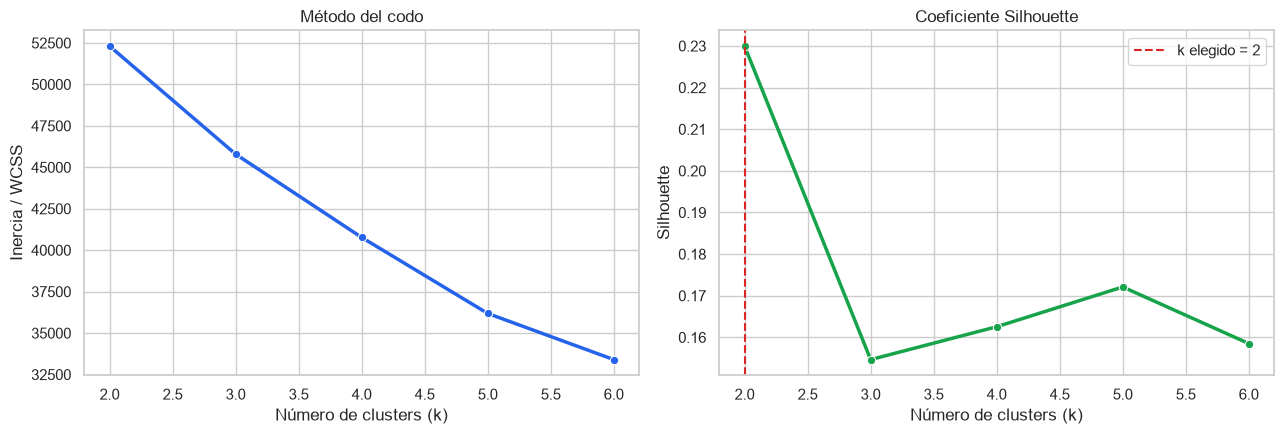

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.lineplot(data=evaluacion, x='k', y='WCSS', marker='o', linewidth=2.5, ax=axes[0], color='#2563eb')
axes[0].set_title('Método del codo')
axes[0].set_xlabel('Número de clusters (k)')
axes[0].set_ylabel('Inercia / WCSS')

sns.lineplot(data=evaluacion, x='k', y='silhouette', marker='o', linewidth=2.5, ax=axes[1], color='#16a34a')
axes[1].axvline(k_optimo, color='#dc2626', linestyle='--', label=f'k elegido = {k_optimo}')
axes[1].set_title('Coeficiente Silhouette')
axes[1].set_xlabel('Número de clusters (k)')
axes[1].set_ylabel('Silhouette')
axes[1].legend()
plt.tight_layout()
plt.show()

## 4. Entrenamiento final y visualización

El modelo final se entrena con el valor de `k` seleccionado. Para visualizar las seis dimensiones en un plano se utiliza PCA. PCA solo se usa para la representación gráfica: los clusters se forman con todas las variables estandarizadas.

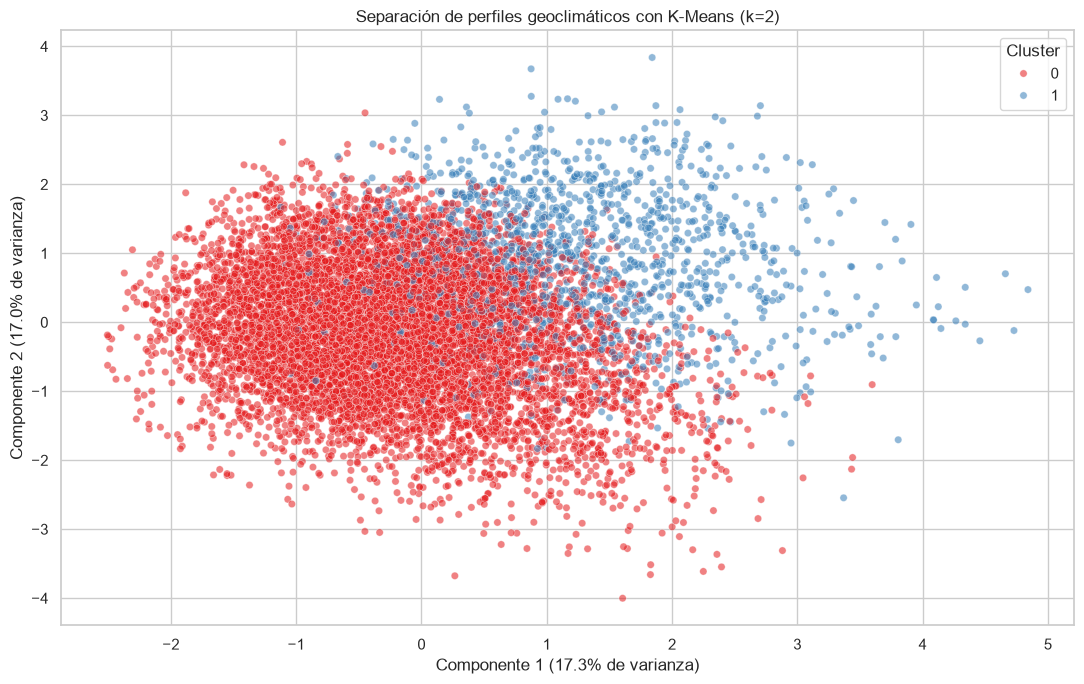

Varianza explicada por los dos componentes: 34.2%


In [6]:
modelo_final = modelos[k_optimo]
clusters = modelo_final.labels_

pca = PCA(n_components=2)
componentes = pca.fit_transform(X_escalado)
grafico = pd.DataFrame({
    'Componente principal 1': componentes[:, 0],
    'Componente principal 2': componentes[:, 1],
    'Cluster': clusters.astype(str)
})

plt.figure(figsize=(11, 7))
sns.scatterplot(
    data=grafico, x='Componente principal 1', y='Componente principal 2',
    hue='Cluster', palette='Set1', alpha=0.55, s=28
)
plt.title(f'Separación de perfiles geoclimáticos con K-Means (k={k_optimo})')
plt.xlabel(f'Componente 1 ({pca.explained_variance_ratio_[0] * 100:.1f}% de varianza)')
plt.ylabel(f'Componente 2 ({pca.explained_variance_ratio_[1] * 100:.1f}% de varianza)')
plt.legend(title='Cluster')
plt.tight_layout()
plt.show()
print(f'Varianza explicada por los dos componentes: {pca.explained_variance_ratio_.sum() * 100:.1f}%')

## 5. Caracterización e interpretación de los clusters

Para explicar cada grupo se calculan sus promedios en las unidades originales. Después se incorporan, solo con fines descriptivos, el índice de riesgo y la ocurrencia de deslizamientos. Esto permite relacionar la segmentación no supervisada con el contexto del proyecto sin introducir esas respuestas durante el entrenamiento.

In [7]:
analisis = df.loc[X_limpio.index, variables + [
    'indice_riesgo_deslizamiento', 'deslizamiento_ocurrido'
]].copy()
analisis['cluster'] = clusters

perfiles = analisis.groupby('cluster').agg(
    registros=('cluster', 'size'),
    lluvia_24h_mm=('precipitacion_24h_mm', 'mean'),
    lluvia_3d_mm=('precipitacion_3d_mm', 'mean'),
    lluvia_7d_mm=('precipitacion_7d_mm', 'mean'),
    pendiente_grados=('pendiente_grados', 'mean'),
    elevacion_m=('elevacion_m', 'mean'),
    humedad_pct=('humedad_pct', 'mean'),
    indice_riesgo=('indice_riesgo_deslizamiento', 'mean'),
    tasa_deslizamiento=('deslizamiento_ocurrido', 'mean')
).round(2)
perfiles['tasa_deslizamiento_pct'] = (perfiles['tasa_deslizamiento'] * 100).round(1)
perfiles.drop(columns='tasa_deslizamiento', inplace=True)
perfiles

,registros,lluvia_24h_mm,lluvia_3d_mm,lluvia_7d_mm,pendiente_grados,elevacion_m,humedad_pct,indice_riesgo,tasa_deslizamiento_pct
cluster,,,,,,,,,
0,8499,14.93,45.13,101.08,30.27,2750.32,59.63,41.81,41.0
1,1501,15.35,43.93,625.04,30.89,2824.03,59.72,55.87,57.0


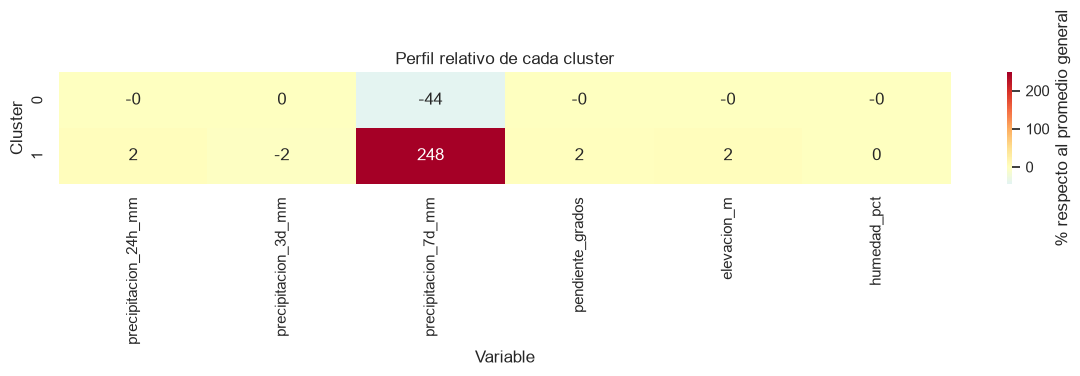

In [8]:
medias_globales = analisis[variables].mean()
perfil_relativo = analisis.groupby('cluster')[variables].mean().div(medias_globales).sub(1).mul(100)

plt.figure(figsize=(12, max(3.5, k_optimo * 1.2)))
sns.heatmap(perfil_relativo, annot=True, fmt='.0f', cmap='RdYlBu_r', center=0, cbar_kws={'label': '% respecto al promedio general'})
plt.title('Perfil relativo de cada cluster')
plt.xlabel('Variable')
plt.ylabel('Cluster')
plt.tight_layout()
plt.show()

In [9]:
orden = perfiles['indice_riesgo'].sort_values().index.tolist()
nombres = {}
for posicion, cluster in enumerate(orden):
    if posicion == 0:
        nombres[cluster] = 'Exposición geoclimática menor'
    elif posicion == len(orden) - 1:
        nombres[cluster] = 'Exposición geoclimática mayor'
    else:
        nombres[cluster] = 'Exposición geoclimática intermedia'

for cluster, fila in perfiles.iterrows():
    print(f"Cluster {cluster} — {nombres[cluster]}")
    print(f"  {int(fila['registros']):,} observaciones; lluvia 7d={fila['lluvia_7d_mm']:.1f} mm; "
          f"pendiente={fila['pendiente_grados']:.1f}°; humedad={fila['humedad_pct']:.1f}%; "
          f"ocurrencia observada={fila['tasa_deslizamiento_pct']:.1f}%.")

cluster_mayor = perfiles['indice_riesgo'].idxmax()
cluster_menor = perfiles['indice_riesgo'].idxmin()
diferencia = perfiles.loc[cluster_mayor, 'tasa_deslizamiento_pct'] - perfiles.loc[cluster_menor, 'tasa_deslizamiento_pct']
print(f'\nHallazgo principal: el cluster {cluster_mayor} presenta la mayor exposición media y una tasa de deslizamiento '      f'de {perfiles.loc[cluster_mayor, "tasa_deslizamiento_pct"]:.1f}%, frente a '      f'{perfiles.loc[cluster_menor, "tasa_deslizamiento_pct"]:.1f}% en el cluster {cluster_menor} '      f'(diferencia de {diferencia:.1f} puntos porcentuales).')

Cluster 0 — Exposición geoclimática menor
  8,499 observaciones; lluvia 7d=101.1 mm; pendiente=30.3°; humedad=59.6%; ocurrencia observada=41.0%.
Cluster 1 — Exposición geoclimática mayor
  1,501 observaciones; lluvia 7d=625.0 mm; pendiente=30.9°; humedad=59.7%; ocurrencia observada=57.0%.

Hallazgo principal: el cluster 1 presenta la mayor exposición media y una tasa de deslizamiento de 57.0%, frente a 41.0% en el cluster 0 (diferencia de 16.0 puntos porcentuales).


## 6. Conclusión

K-Means permite resumir miles de observaciones en perfiles geoclimáticos comprensibles. La combinación del coeficiente Silhouette y el método del codo proporciona una justificación cuantitativa para elegir el número de clusters, mientras que PCA y el mapa de calor ayudan a comunicar su separación y características.

El hallazgo relevante es que los grupos formados sin conocer la variable objetivo presentan diferencias observables en el índice y en la frecuencia histórica de deslizamientos. Por ello, la clusterización aporta una capa descriptiva útil para priorizar el análisis de zonas con perfiles semejantes. Sin embargo, los clusters representan asociaciones y no causalidad ni niveles oficiales de alerta. Para una aplicación real se requiere validar el procedimiento con datos de campo, información temporal y evaluación por especialistas.